In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_csv("../data/processed/dataset_limpio.csv")
df["Antiguedad"] = 2026 - df["Año"]

print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")
print("\nValores nulos:\n", df.isnull().sum())
display(df.describe().round(2))

Dimensiones: 372 filas x 9 columnas

Valores nulos:
 Marca          0
Modelo         0
Año            0
Motor          0
Kilometraje    0
Transmisión    0
Combustible    0
Precio         0
Antiguedad     0
dtype: int64


,Año,Motor,Kilometraje,Precio,Antiguedad
count,372.00,372.00,372.00,372.00,372.00
mean,2018.27,2.15,99436.13,12380.21,7.73
std,5.01,0.72,60582.81,7351.59,5.01
min,2000.00,1.00,1000.00,2300.00,0.00
25%,2016.00,1.60,59000.00,7900.00,4.00
50%,2019.00,2.00,91158.00,10850.00,7.00
75%,2022.00,2.50,123158.00,14800.00,10.00
max,2026.00,5.60,414382.00,68000.00,26.00


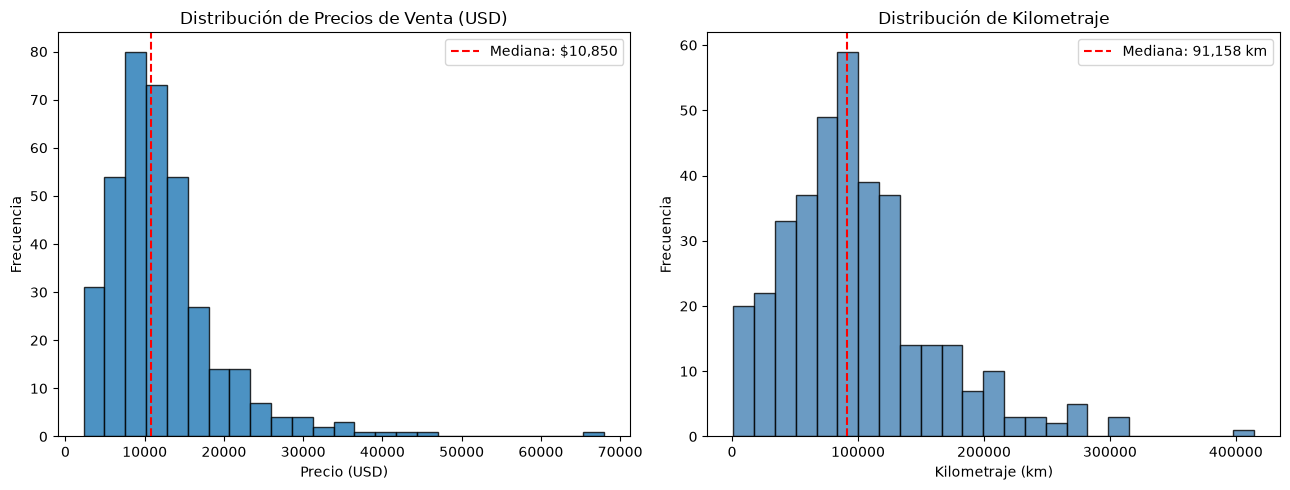

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(df["Precio"], bins=25, edgecolor="black", alpha=0.8)
axes[0].axvline(df["Precio"].median(), color="red", linestyle="--", label=f"Mediana: ${df['Precio'].median():,.0f}")
axes[0].set_title("Distribución de Precios de Venta (USD)")
axes[0].set_xlabel("Precio (USD)")
axes[0].set_ylabel("Frecuencia")
axes[0].legend()

axes[1].hist(df["Kilometraje"], bins=25, edgecolor="black", alpha=0.8, color="steelblue")
axes[1].axvline(df["Kilometraje"].median(), color="red", linestyle="--", label=f"Mediana: {df['Kilometraje'].median():,.0f} km")
axes[1].set_title("Distribución de Kilometraje")
axes[1].set_xlabel("Kilometraje (km)")
axes[1].set_ylabel("Frecuencia")
axes[1].legend()

plt.tight_layout()
plt.savefig("../docs/eda_distribuciones.png", dpi=150)
plt.show()

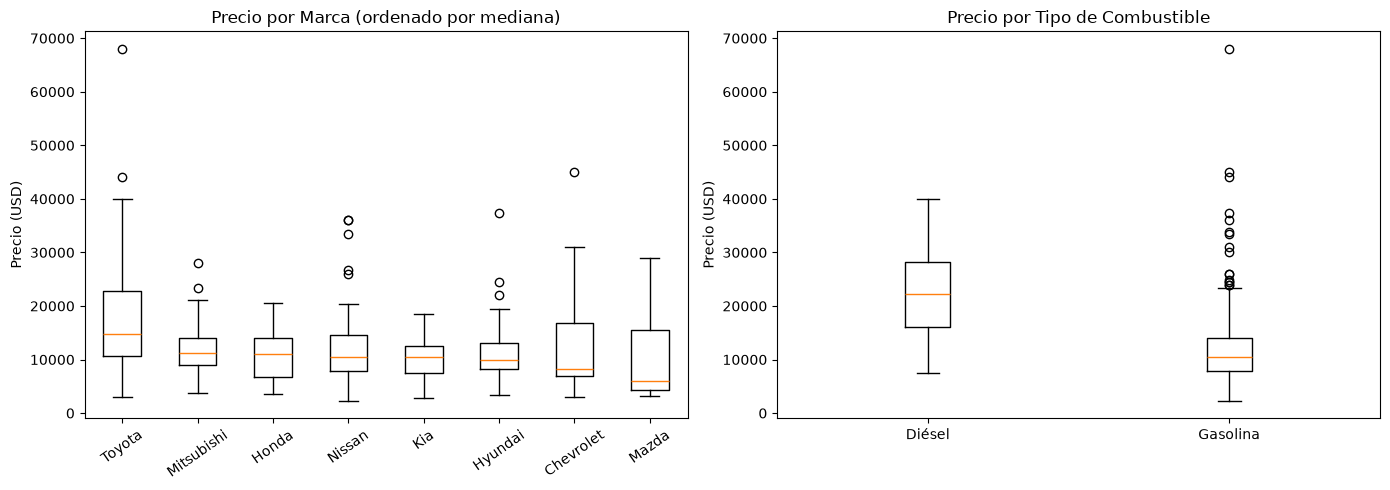

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

orden_marcas = df.groupby("Marca")["Precio"].median().sort_values(ascending=False).index
datos_marcas = [df.loc[df["Marca"] == m, "Precio"] for m in orden_marcas]
axes[0].boxplot(datos_marcas, tick_labels=orden_marcas)
axes[0].set_title("Precio por Marca (ordenado por mediana)")
axes[0].set_ylabel("Precio (USD)")
axes[0].tick_params(axis="x", rotation=35)

combustibles = ["Diésel", "Gasolina"]
datos_comb = [df.loc[df["Combustible"] == c, "Precio"] for c in combustibles]
axes[1].boxplot(datos_comb, tick_labels=combustibles)
axes[1].set_title("Precio por Tipo de Combustible")
axes[1].set_ylabel("Precio (USD)")

plt.tight_layout()
plt.savefig("../docs/eda_boxplots.png", dpi=150)
plt.show()

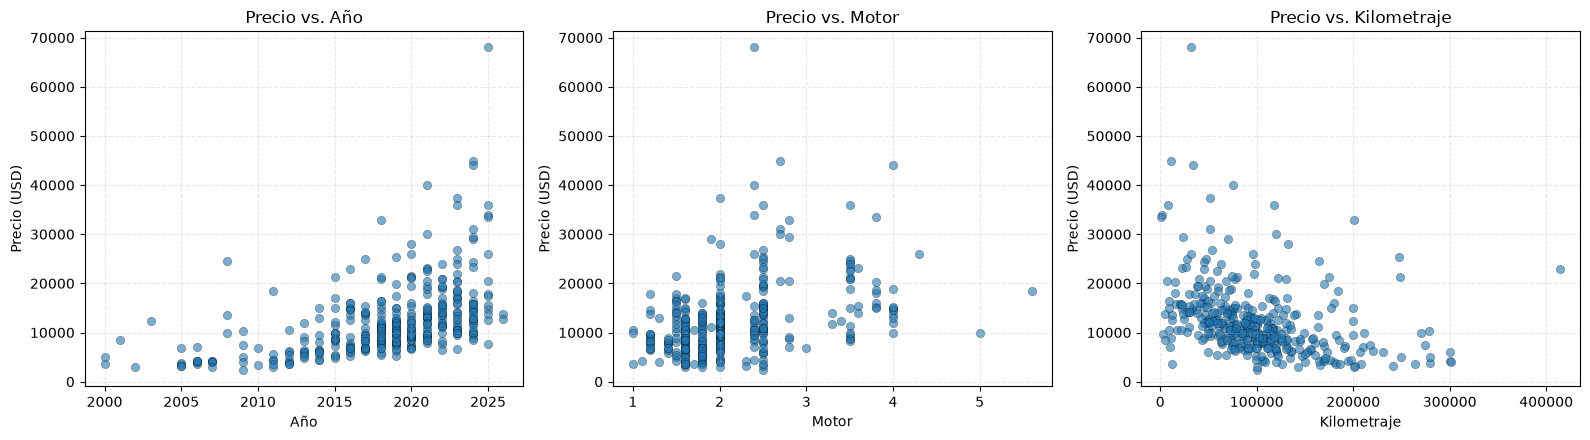

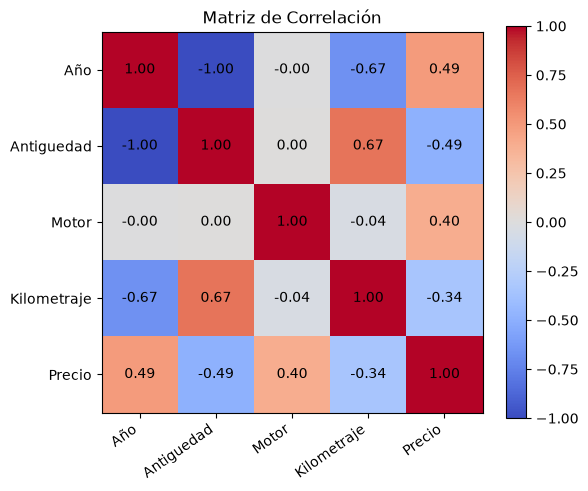

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, col in zip(axes, ["Año", "Motor", "Kilometraje"]):
    ax.scatter(df[col], df["Precio"], alpha=0.6, edgecolors="k", linewidth=0.3)
    ax.set_title(f"Precio vs. {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Precio (USD)")
    ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig("../docs/eda_dispersion.png", dpi=150)
plt.show()

corr = df[["Año", "Antiguedad", "Motor", "Kilometraje", "Precio"]].corr()
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=35, ha="right")
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", color="black")
plt.colorbar(im)
plt.title("Matriz de Correlación")
plt.tight_layout()
plt.savefig("../docs/eda_correlacion.png", dpi=150)
plt.show()